In [214]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline 
import warnings

warnings.filterwarnings('ignore')

In [215]:
train = pd.read_csv("D:\ML smart loan prediction\loan_sanction_train.csv",engine="python",on_bad_lines="skip")
test = pd.read_csv("D:\ML smart loan prediction\loan_sanction_test.csv",engine="python",on_bad_lines="skip")

In [216]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [217]:
test.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban


In [218]:
train.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [219]:
test.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,367.000000,367.000000,362.000000,361.000000,338.000000
mean,4805.599455,1569.577657,136.132597,342.537396,0.825444
std,4910.685399,2334.232099,61.366652,65.156643,0.380150
min,0.000000,0.000000,28.000000,6.000000,0.000000
25%,2864.000000,0.000000,100.250000,360.000000,1.000000
50%,3786.000000,1025.000000,125.000000,360.000000,1.000000
75%,5060.000000,2430.500000,158.000000,360.000000,1.000000
max,72529.000000,24000.000000,550.000000,480.000000,1.000000


In [220]:
# it is safe to store original data before performing any actions
train_original = train.copy()
test_original = test.copy()

In [221]:
train.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area', 'Loan_Status'],
      dtype='str')

In [222]:
test.columns

Index(['Loan_ID', 'Gender', 'Married', 'Dependents', 'Education',
       'Self_Employed', 'ApplicantIncome', 'CoapplicantIncome', 'LoanAmount',
       'Loan_Amount_Term', 'Credit_History', 'Property_Area'],
      dtype='str')

In [223]:
# while perfoeming the eda and all if we notice any requirement for changing datatype we have to do it
train.dtypes

Loan_ID                  str
Gender                   str
Married                  str
Dependents               str
Education                str
Self_Employed            str
ApplicantIncome        int64
CoapplicantIncome    float64
LoanAmount           float64
Loan_Amount_Term     float64
Credit_History       float64
Property_Area            str
Loan_Status              str
dtype: object

In [224]:
train.shape, test.shape

((614, 13), (367, 12))

In [225]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 62.5 KB


# EDA

In [226]:
# we have to start with the target variable start analizing the target variable and normalize it.
train["Loan_Status"].value_counts()

Loan_Status
Y    422
N    192
Name: count, dtype: int64

In [227]:
train["Loan_Status"].value_counts(normalize=True)

Loan_Status
Y    0.687296
N    0.312704
Name: proportion, dtype: float64

<Axes: xlabel='Loan_Status'>

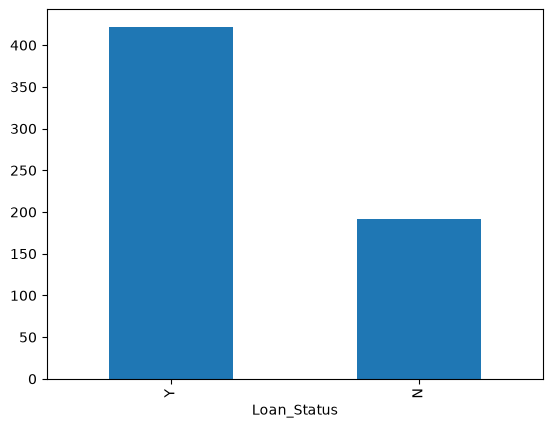

In [228]:
train["Loan_Status"].value_counts().plot.bar()

Now lets visualize each variable separately.

1. Categorical features These features have categories ( Gender, Married, Self_Employed, Credit_History, Loan_Status )

2. Ordinal features: Variables in categorical features having some order involved ( Dependents , Education, Property_Area)

3. Numerical features These features have numerical values ( ApplicantIncome , CoapplicantIncome, LoanAmount , Loan_Amount_Term)

Lets visualize the categorical and ordinal features first.

Categorical features

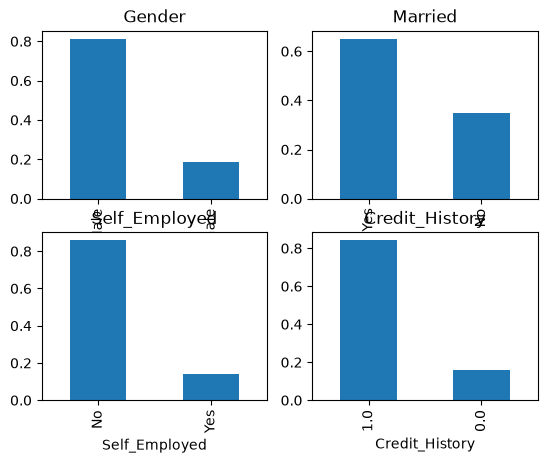

In [229]:
plt.figure(1)
plt.subplot(221) # (rows,col,plot_num)
train['Gender'].value_counts(normalize=True).plot.bar(title="Gender")
plt.subplot(222)
train['Married'].value_counts(normalize=True).plot.bar(title="Married")
plt.subplot(223)
train['Self_Employed'].value_counts(normalize=True).plot.bar(title="Self_Employed")
plt.subplot(224)
train['Credit_History'].value_counts(normalize=True).plot.bar(title="Credit_History")
plt.show()


Ordinal features

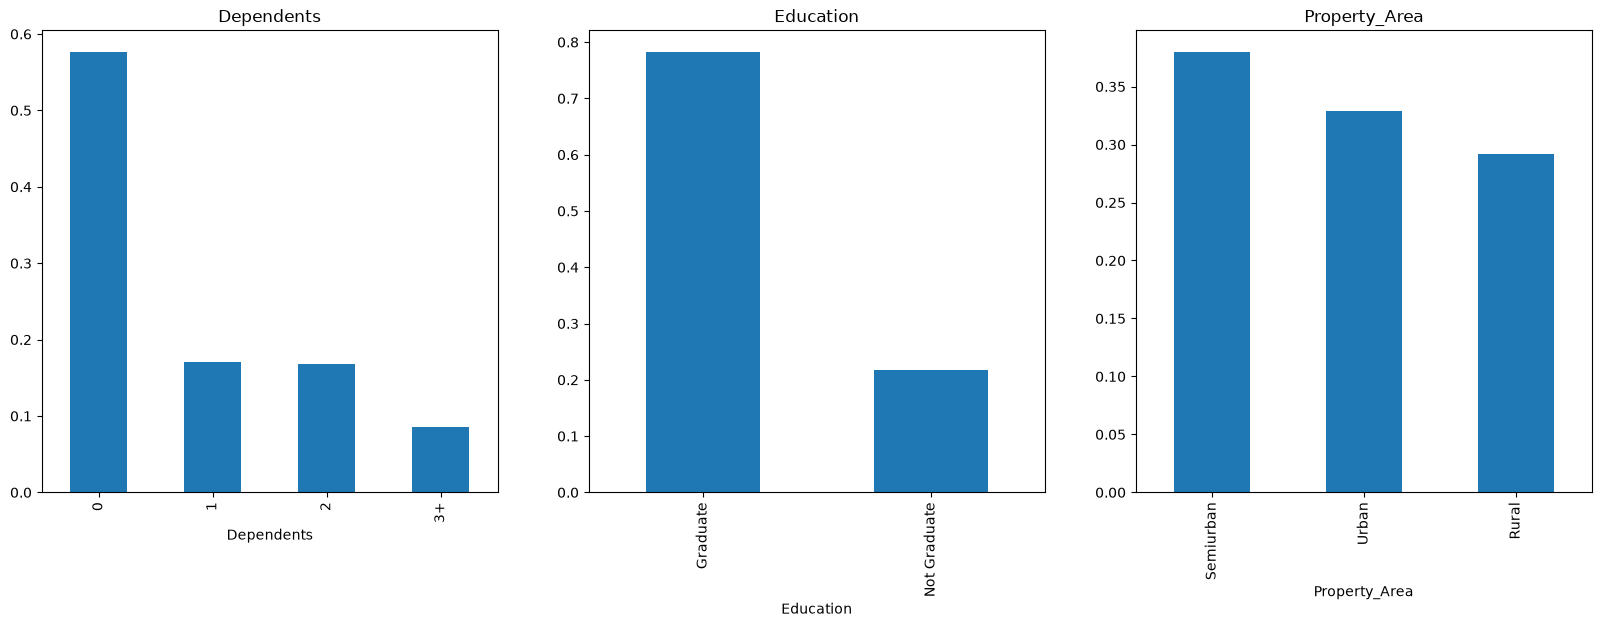

In [230]:
plt.figure(1)
plt.subplot(131)
train['Dependents'].value_counts(normalize=True).plot.bar(figsize = (20,6), title='Dependents')

plt.subplot(132)
train['Education'].value_counts(normalize=True).plot.bar(title= 'Education')

plt.subplot(133)
train['Property_Area' ].value_counts(normalize=True).plot.bar(title= 'Property_Area')

plt.show()

Independent features

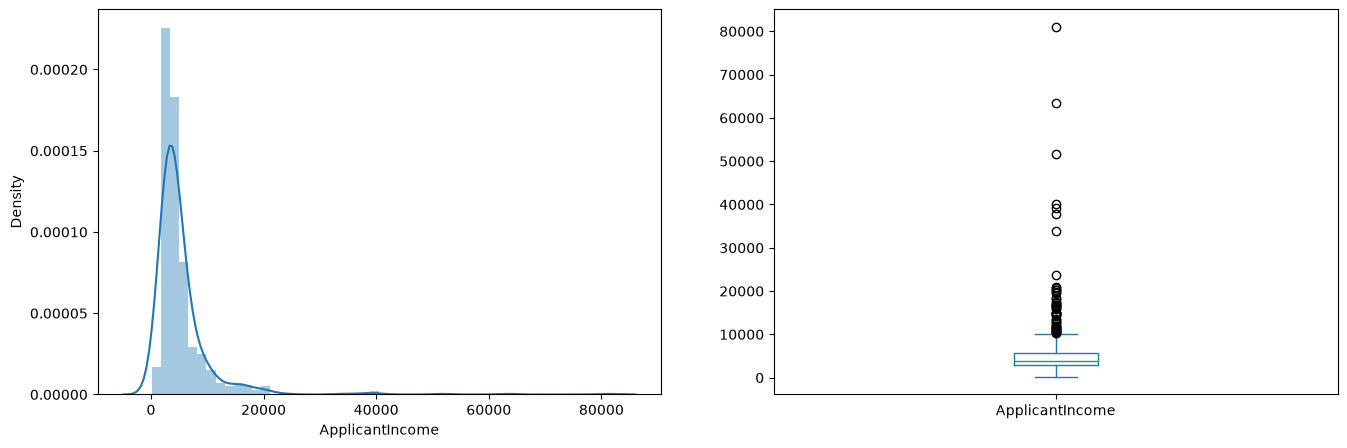

In [231]:
plt.figure(1)
plt.subplot(121)
sns.distplot(train['ApplicantIncome' ])

plt.subplot(122)
train['ApplicantIncome'].plot.box(figsize=(16,5))

plt.show()

. Applicant income is not normally distributed. We should make it normal as algorithm works better if the data is normally distributed.

. Boxplot confirms the presence of outliers/extreme values. This can be attributed to the income disparity in the society.

. Lets segregate them by Education

In [ ]:
train.boxplot(column="ApplicantIncome", by="Education")
plt.suptitle("")

Text(0.5, 0.98, '')

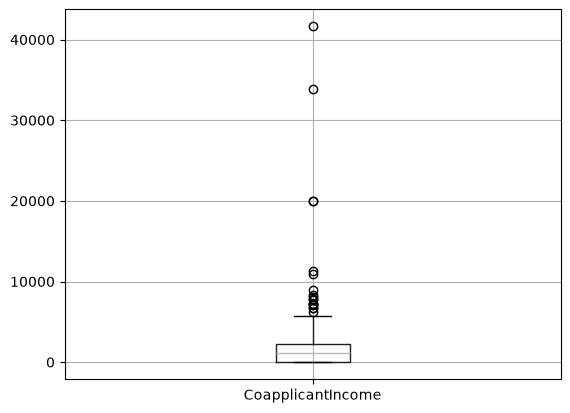

In [ ]:
train.boxplot(column="CoapplicantIncome")
plt.show()

<Axes: >

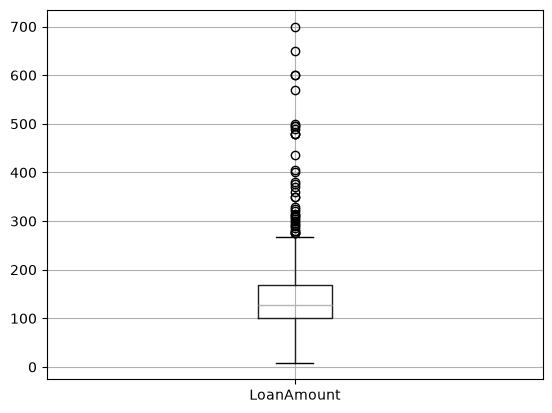

In [ ]:
train.boxplot(column="LoanAmount")

# Bivariate Analysis 
Categorical Independent Variable v/s Target Variable

In [ ]:
train.columns
train.head(10)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N


<Axes: xlabel='Gender'>

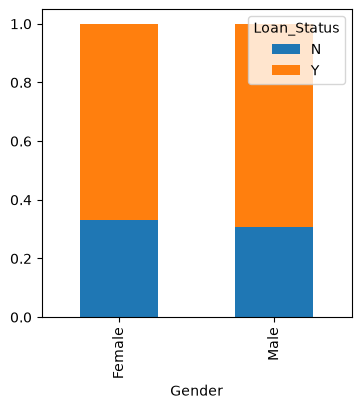

In [ ]:
Gender = pd.crosstab(train['Gender'], train['Loan_Status'])
Gender.div(Gender.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))

<Axes: xlabel='Self_Employed'>

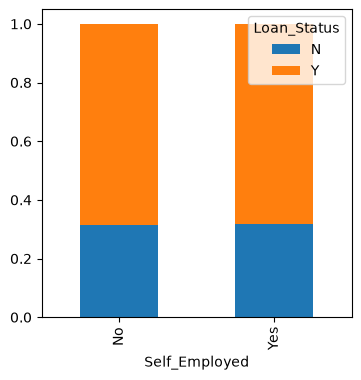

In [ ]:
Self_employed = pd.crosstab(train['Self_Employed'], train['Loan_Status'])
Self_employed.div(Self_employed.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))

<Axes: xlabel='Married'>

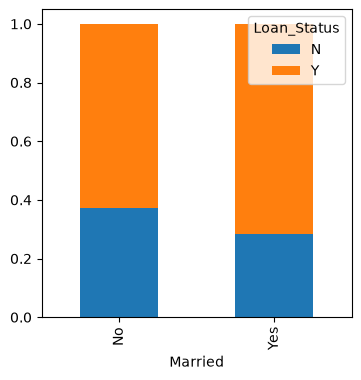

In [ ]:
married = pd.crosstab(train['Married'], train['Loan_Status'])
married.div(married.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))

<Axes: xlabel='Credit_History'>

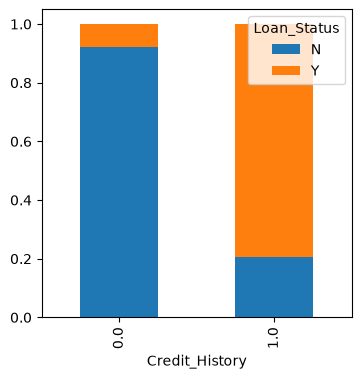

In [ ]:
credit_history = pd.crosstab(train['Credit_History'], train['Loan_Status'])
credit_history.div(credit_history.sum(1).astype(float), axis =0).plot(kind="bar",stacked=True,figsize=(4,4))
# here the observation is the people with low credit history mostly not getting the loan

here we can divide the income into some bins and then we can do the comparistions

<Axes: xlabel='Coapplicant_Income_bin'>

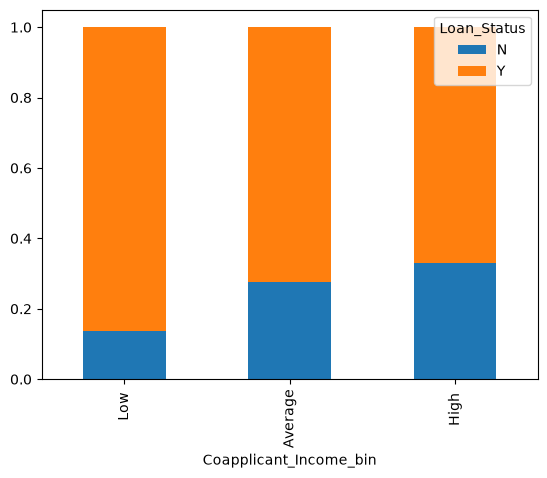

In [ ]:
bins = [0,1000,3000,42000] # before creating the bins range we have to go through the data and the we have to desicde the bins range
groups = ["Low ","Average","High "]

train["Coapplicant_Income_bin"] = pd.cut(train["CoapplicantIncome"],bins,labels=groups)

Coapplicant_Income_bin=pd.crosstab(train['Coapplicant_Income_bin'],train['Loan_Status'])
Coapplicant_Income_bin.div(Coapplicant_Income_bin.sum(1).astype(float), axis=0).plot(kind='bar',stacked=True)   


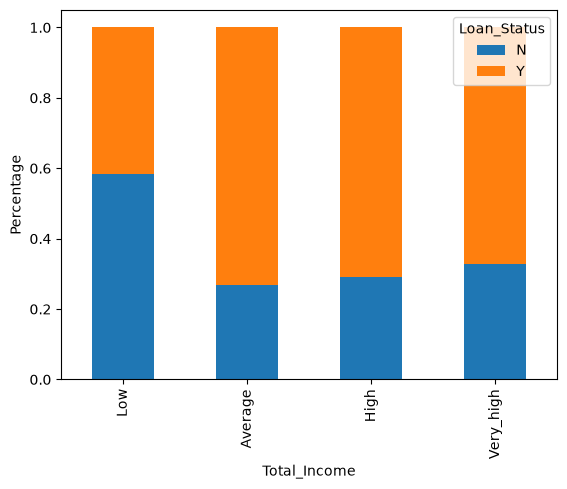

In [ ]:
train['Total_Income'] = train['ApplicantIncome'] + train['CoapplicantIncome']

bins = [0,2500,4000,6000,81000]
group = ['Low', 'Average', 'High', 'Very_high']

train['Total_Income_bin']=pd.cut(train['Total_Income'],bins,labels=group)

Total_Income_bin=pd.crosstab(train['Total_Income_bin'],train['Loan_Status'])
Total_Income_bin.div(Total_Income_bin.sum(1).astype(float), axis=0).plot(kind="bar", stacked=True)

plt.xlabel('Total_Income')
P = plt.ylabel('Percentage')

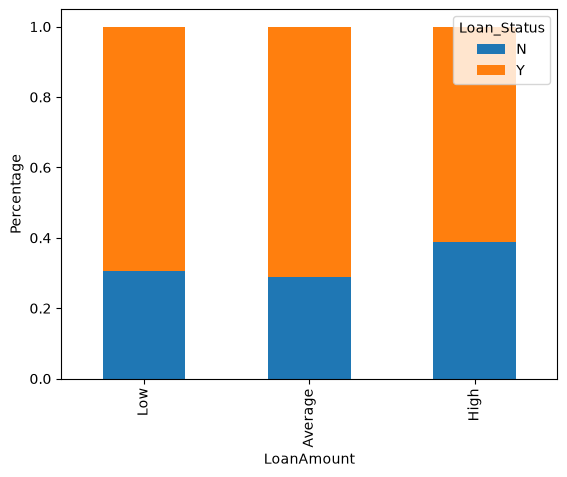

In [ ]:
bins=[0,100,200,700]
group=['Low','Average','High']

train['LoanAmount_bin']=pd.cut(train['LoanAmount'],bins,labels=group)

LoanAmount_bin=pd.crosstab(train['LoanAmount_bin'],train['Loan_Status'])
LoanAmount_bin.div(LoanAmount_bin.sum(1).astype(float), axis=0).plot(kind="bar", stacked=True)

plt.xlabel('LoanAmount')
P = plt.ylabel('Percentage')

<Axes: xlabel='Credit_History'>

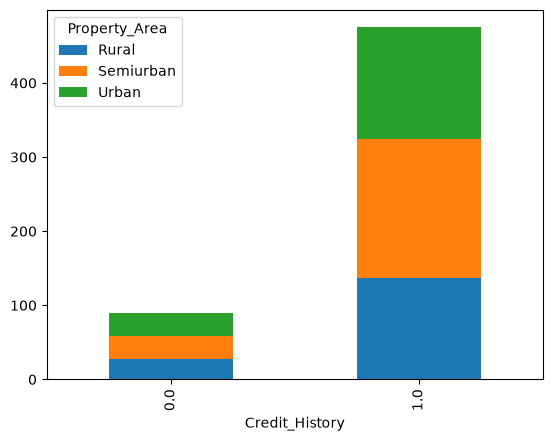

In [ ]:
# credit history vs property area bar plot
pd.crosstab(train['Credit_History'], train['Property_Area']).plot(kind='bar',stacked=True)

In [ ]:
train.head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,Coapplicant_Income_bin,Total_Income,Total_Income_bin,LoanAmount_bin
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y,NaN,5849.0,High,NaN
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N,Average,6091.0,Very_high,Average
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y,NaN,3000.0,Average,Low
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y,Average,4941.0,High,Average
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y,NaN,6000.0,High,Average
5,LP001011,Male,Yes,2,Graduate,Yes,5417,4196.0,267.0,360.0,1.0,Urban,Y,High,9613.0,Very_high,High
6,LP001013,Male,Yes,0,Not Graduate,No,2333,1516.0,95.0,360.0,1.0,Urban,Y,Average,3849.0,Average,Low
7,LP001014,Male,Yes,3+,Graduate,No,3036,2504.0,158.0,360.0,0.0,Semiurban,N,Average,5540.0,High,Average
8,LP001018,Male,Yes,2,Graduate,No,4006,1526.0,168.0,360.0,1.0,Urban,Y,Average,5532.0,High,Average
9,LP001020,Male,Yes,1,Graduate,No,12841,10968.0,349.0,360.0,1.0,Semiurban,N,High,23809.0,Very_high,High


In [ ]:
train = train.drop([ 'Coapplicant_Income_bin', 'LoanAmount_bin', 'Total_Income'], axis=1)

In [ ]:
train['Dependents'].replace('3+', 3,inplace=True)
test['Dependents'].replace('3+', 3,inplace=True)
train['Loan_Status'].replace('N', 0,inplace=True)
train['Loan_Status'].replace('Y', 1,inplace=True)

0      1
1      N
2      1
3      1
4      1
      ..
609    1
610    1
611    1
612    1
613    N
Name: Loan_Status, Length: 614, dtype: object

In [ ]:
train.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
# Now we have to see the realtion b/w features
numerical_df = train.select_dtypes(include=['int64', 'float64'])
# Here are the above code store al numeric features into it

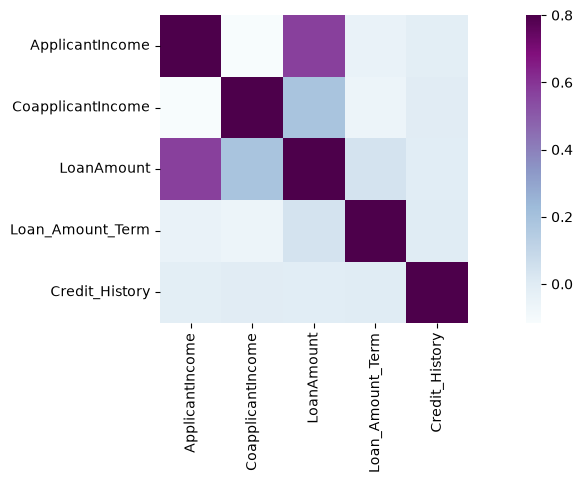

In [ ]:
matrix = numerical_df.corr()
f, ax = plt.subplots(figsize=(15,4))
sns.heatmap(matrix, vmax=.8, square=True, cmap="BuPu");

# Missing value Imputation

In [ ]:
train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

In [ ]:
train['Gender'] = train['Gender'].fillna(train['Gender'].mode()[0])
train['Married'] = train['Married'].fillna(train['Married'].mode()[0])
train['Dependents'] = train['Dependents'].fillna(train['Dependents'].mode()[0])
train['Self_Employed'] = train['Self_Employed'].fillna(train['Self_Employed'].mode()[0])
train['Credit_History'] = train['Credit_History'].fillna(train['Credit_History'].mode()[0])

In [ ]:
train['Loan_Amount_Term'].value_counts()

Loan_Amount_Term
360.0    512
180.0     44
480.0     15
300.0     13
240.0      4
84.0       4
120.0      3
60.0       2
36.0       2
12.0       1
Name: count, dtype: int64

In [ ]:
train['Loan_Amount_Term'] = train['Loan_Amount_Term'].fillna(train['Loan_Amount_Term'].mode()[0])
train['LoanAmount'] = train['LoanAmount'].fillna(train['LoanAmount'].median())

In [ ]:
train.isnull().sum()

Loan_ID               0
Gender                0
Married               0
Dependents            0
Education             0
Self_Employed         0
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount            0
Loan_Amount_Term      0
Credit_History        0
Property_Area         0
Loan_Status           0
LoanAmount_log       22
dtype: int64

In [ ]:
# Fill categorical and numerical columns in the test set using train statistics
test['Gender'] = test['Gender'].fillna(train['Gender'].mode()[0])
test['Dependents'] = test['Dependents'].fillna(train['Dependents'].mode()[0])
test['Self_Employed'] = test['Self_Employed'].fillna(train['Self_Employed'].mode()[0])
test['Credit_History'] = test['Credit_History'].fillna(train['Credit_History'].mode()[0])
test['Loan_Amount_Term'] = test['Loan_Amount_Term'].fillna(train['Loan_Amount_Term'].mode()[0])
test['LoanAmount'] = test['LoanAmount'].fillna(train['LoanAmount'].median())

# Out layer treatment

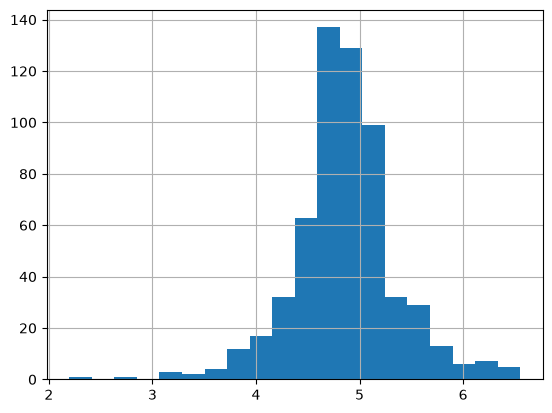

In [ ]:
# Out layers means the values which are in different range from all other values and that values effects the remaining
# We havr to remove them or tranform them by appling log 
train["LoanAmount_log"] = np.log(train["LoanAmount"])
train["LoanAmount_log"].hist(bins=20)
test["LoanAmount_log"] = np.log(test["LoanAmount"])
 

# Feature Engineering

1. Binary Encoding 
2. One-Hot-Encoding
3. Label Encoding

In [ ]:
# binary encoding on train data
train['Gender'] = train['Gender'].map({'Male': 1, 'Female': 0})
train['Married'] = train['Married'].map({'Yes': 1, 'No': 0})
train['Education'] = train['Education'].map({'Graduate': 1, 'Not Graduate': 0})
train['Self_Employed'] = train['Self_Employed'].map({'Yes': 1, 'No': 0})

In [ ]:
# binary encoding on test data
test['Gender'] = test['Gender'].map({'Male': 1, 'Female': 0})
test['Married'] = test['Married'].map({'Yes': 1, 'No': 0})
test['Education'] = test['Education'].map({'Graduate': 1, 'Not Graduate': 0})
test['Self_Employed'] = test['Self_Employed'].map({'Yes': 1, 'No': 0})

In [ ]:
train.head(20)

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status,LoanAmount_log
0,LP001002,1.0,0.0,0,1,0.0,5849,0.0,NaN,360.0,1.0,Urban,Y,NaN
1,LP001003,1.0,1.0,1,1,0.0,4583,1508.0,128.0,360.0,1.0,Rural,N,4.852030
2,LP001005,1.0,1.0,0,1,1.0,3000,0.0,66.0,360.0,1.0,Urban,Y,4.189655
3,LP001006,1.0,1.0,0,0,0.0,2583,2358.0,120.0,360.0,1.0,Urban,Y,4.787492
4,LP001008,1.0,0.0,0,1,0.0,6000,0.0,141.0,360.0,1.0,Urban,Y,4.948760
5,LP001011,1.0,1.0,2,1,1.0,5417,4196.0,267.0,360.0,1.0,Urban,Y,5.587249
6,LP001013,1.0,1.0,0,0,0.0,2333,1516.0,95.0,360.0,1.0,Urban,Y,4.553877
7,LP001014,1.0,1.0,3+,1,0.0,3036,2504.0,158.0,360.0,0.0,Semiurban,N,5.062595
8,LP001018,1.0,1.0,2,1,0.0,4006,1526.0,168.0,360.0,1.0,Urban,Y,5.123964
9,LP001020,1.0,1.0,1,1,0.0,12841,10968.0,349.0,360.0,1.0,Semiurban,N,5.855072


In [ ]:
train.isnull().sum()

Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
LoanAmount_log       22
dtype: int64